# Random Forest — the shared 29-feature early-warning task

Mirrors `train_transformer.ipynb`, with reusable code in `src/random_forest/` and a separate results notebook, `random_forest_results.ipynb`.

- **Target:** measured speed **<40 mph at any of the next six five-minute readings**, excluding the current reading.
- **Validation:** six quarterly walk-forward folds, 2024 Q1–2025 Q2, with the shared seven-day gap and full-window boundary purging.
- **Inputs:** all **29 features currently in `sf.SHARED_FEATURES`**, including the transformer additions. The shared module is unchanged.
- **Training/scoring:** train on known measured future outcomes, predict every validation row, and use the shared scoring functions. AP onsets is row-level AP among currently uncongested, measured stations; episode recall ≥15 min is a separate metric.
- **Holdout:** July–December 2025 is never loaded or scored.

Start with `QUICK_RUN = True`. A quick run uses the last fold, 50 trees, and at most 200,000 training endpoints, and never updates the team table. Set `False` to run all six folds with 300 trees and the team's 2-million-row training cap. Forests use quarter-size bootstrap samples to bound cost. No validation-selected checkpoint or hyperparameter search is performed here.

## Completed six-fold run

The saved run uses **all 29 shared features**, a new 300-tree Random Forest per quarter, and the team's training sampling convention. A last-fold quick test was completed first without modifying the team summary. The final July–December 2025 holdout was excluded.

| Measure | Six-fold result |
|---|---:|
| Mean AP onsets | 0.7495 |
| Standard deviation of AP | 0.0088 |
| Worst-quarter AP | 0.7384 |
| Mean Brier score | 0.0230 |
| Onsets caught ≥15 min ahead at 0.5 | 52.6% |
| False-warning episodes per day at 0.5 | 30.05 |
| Wrong-alert hours per day at 0.5 | 4.46 |

AP is a row-level ranking measure on the shared primary population; the caught-onsets measure is episode-level. The alert metrics use the default 0.5 cutoff. Use the saved tradeoff curve before choosing a warning budget. These are development results, not final holdout estimates.

Local artifacts: `src/random_forest/results/random_forest_shared_29_features_full_20261031_200713_030817`. Team comparison files are in `notebooks/results/`. `random_forest_results.ipynb` loads the saved probabilities and models' diagnostics without retraining. The model uses the 29-feature current vector; the recorded transformer uses a historical sequence, so their comparison is between model systems.

The training notebook retains the executed full-run settings (`QUICK_RUN = False`). Set it to `True` before a future smoke test. This static summary describes the saved run and should be updated after rerunning with new settings.


In [1]:
from pathlib import Path
import sys
PROJECT_DIR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "notebooks" / "safeflow_features.py").exists() and (p / "data").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start the kernel in the SafeFlow project or a subdirectory")
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))
import gc
import json
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import safeflow_features as sf
from src.random_forest import random_forest_training as training
LOCAL_DIR = PROJECT_DIR / "src" / "random_forest"
TEAM_RESULTS = PROJECT_DIR / "notebooks" / "results"
pd.set_option("display.width", 160)

## Settings

In [2]:
MODEL_NAME = "random_forest_shared_29_features"
QUICK_RUN = False
TRAIN_SAMPLE = 200_000 if QUICK_RUN else 2_000_000
SAMPLE_SEED, MODEL_SEED = 0, 42
USE_DATASET_CACHE = True  # fingerprinted, fold-independent development features only
SAVE_MODELS = True
MODEL_PARAMETERS = dict(n_estimators=50 if QUICK_RUN else 300, max_depth=12,
                        min_samples_leaf=10, max_samples=0.25, n_jobs=-1, random_state=MODEL_SEED)
DATA_DIR = next((p for p in [PROJECT_DIR / "data", PROJECT_DIR / "Data"] if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Set DATA_DIR to the D12 data folder")
if not (DATA_DIR / sf.META_FILE_NAME).exists():
    raise FileNotFoundError(DATA_DIR / sf.META_FILE_NAME)
RUN_DIR = LOCAL_DIR / "results" / f"{MODEL_NAME}_{'quick' if QUICK_RUN else 'full'}_{datetime.now():%Y%m%d_%H%M%S_%f}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Mode:", "LAST-FOLD QUICK TEST" if QUICK_RUN else "ALL SIX FOLDS", flush=True)
print("Data:", DATA_DIR, "\nLocal outputs:", RUN_DIR, "\nTeam results:", TEAM_RESULTS, flush=True)
print("Model parameters:", MODEL_PARAMETERS, flush=True)

Mode: ALL SIX FOLDS
Data: C:\Erdos\Project\safeflow\data 
Local outputs: C:\Erdos\Project\safeflow\src\random_forest\results\random_forest_shared_29_features_full_20261031_200713_030817 
Team results: C:\Erdos\Project\safeflow\notebooks\results
Model parameters: {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 10, 'max_samples': 0.25, 'n_jobs': -1, 'random_state': 42}


## 1. Load shared development features

The optional local cache is fingerprinted using the shared source, feature list, metadata, and pre-holdout input file sizes/mtimes. It contains only fold-independent features and labels. Typical-condition features are recomputed from each fold's training data; they are not reused across folds.

In [3]:
df, dataset_fingerprint = training.load_dataset(sf, DATA_DIR, use_cache=USE_DATASET_CACHE)
FEATURES = list(sf.SHARED_FEATURES)
assert len(FEATURES) == 29, "The shared contract changed; review the requested 29-feature experiment before rerunning"
assert len(set(FEATURES)) == 29 and not set(FEATURES).intersection(sf.FUTURE_COLUMNS)
assert df["timestamp"].max() < pd.Timestamp(sf.HOLDOUT_START)
folds = list(sf.folds(df, only_last=QUICK_RUN))
all_folds = list(sf.folds(df))
manifest = dict(model=MODEL_NAME, quick_run=QUICK_RUN, status="running", run_dir=str(RUN_DIR),
    features=FEATURES, feature_sha256=training.feature_hash(FEATURES),
    shared_code_sha256=training.sha256_file(sf.__file__), dataset_fingerprint=dataset_fingerprint,
    training_code_sha256=training.sha256_file(training.__file__),
    factory_code_sha256=training.sha256_file(LOCAL_DIR / "safeflow_random_forest.py"),
    versions=training.versions(), model_parameters=MODEL_PARAMETERS, train_sample=TRAIN_SAMPLE,
    sample_seed=SAMPLE_SEED, validation_quarters=sf.VALIDATION_QUARTERS,
    gap_days=sf.GAP_DAYS, holdout_start=sf.HOLDOUT_START, forecast_minutes=sf.WINDOW_MIN,
    slow_mph=sf.SLOW_MPH, alert_threshold=sf.ALERT_THRESHOLD, min_lead_minutes=sf.MIN_LEAD_MIN,
    expected_fold_names=[fold.name for fold in all_folds], completed_fold_names=[])
training.write_json(RUN_DIR / "manifest.json", manifest)
print(f"{len(df):,} rows, {df.station.nunique()} stations; {len(FEATURES)} logical features", flush=True)
print("Folds:", [fold.name for fold in folds], flush=True)
display(pd.DataFrame({"feature": FEATURES}))

Loading matching local development cache: C:\Erdos\Project\safeflow\src\random_forest\cache\development_343e4e0462efaa0f.parquet
4,819,328 rows, 46 stations; 29 logical features
Folds: ['2024-01 to 2024-03', '2024-04 to 2024-06', '2024-07 to 2024-09', '2024-10 to 2024-12', '2025-01 to 2025-03', '2025-04 to 2025-06']


,feature
0,speed_anomaly
1,occ_anomaly
2,typical_congestion_30
3,speed_delta_2
4,flow
5,down_minus_here
6,up_minus_here
7,tod_sin
8,tod_cos
9,dow


## 2. Train and validate

Each fold gets new median imputation, missingness indicators, weekday encoding, and an unfitted forest. Random Forest requires no feature scaling. The forest has no class weighting so its probabilities reflect the observed training population. Training rows are sampled with seed 0, matching the team convention; typical-condition summaries still use the complete fold training period.

Every fold saves its fitted pipeline, predictions, preprocessing details, and metrics before continuing. All output locations are explicit, so starting the notebook from another project subdirectory cannot redirect the results.

In [4]:
fold_rows, prediction_parts = [], []
for fold in folds:
    print(f"\n{fold.name}: recomputing training-only typical features", flush=True)
    sf.add_typical_features(df, fold.train)
    if training.sha256_file(sf.__file__) != manifest["shared_code_sha256"]:
        raise RuntimeError("The shared module changed during this run; restart to avoid a mixed contract")
    train_rows = np.flatnonzero((fold.train & df["y_known"]).to_numpy())
    if TRAIN_SAMPLE is not None and len(train_rows) > TRAIN_SAMPLE:
        train_rows = pd.Series(train_rows).sample(TRAIN_SAMPLE, random_state=SAMPLE_SEED).to_numpy()
    train_rows = np.sort(train_rows)
    val_rows = np.flatnonzero(fold.val.to_numpy())
    fold_dir = RUN_DIR / fold.name[:7]
    result = training.fit_fold(df, FEATURES, train_rows, val_rows, fold_dir,
                                model_parameters=MODEL_PARAMETERS, save_model=SAVE_MODELS)
    assert np.array_equal(result["positions"], val_rows)
    val = df.iloc[val_rows]
    probability = result["probability"]
    metrics = sf.score(val, probability)
    row = dict(fold=fold.name, **metrics, train_rows=len(train_rows), validation_rows=len(val_rows),
               encoded_features=result["encoded_features"], fit_seconds=result["fit_seconds"])
    fold_rows.append(row)
    kept = val[sf.KEY + ["date", "y", "y_known", "congested_now", "real", "onset"]].copy()
    kept["fold"], kept["probability"] = fold.name, probability
    kept.to_parquet(fold_dir / "validation_predictions.parquet", index=False)
    prediction_parts.append(kept)
    training.write_json(fold_dir / "metrics.json", row)
    pd.DataFrame(fold_rows).to_csv(RUN_DIR / "fold_results.csv", index=False)
    manifest["completed_fold_names"].append(fold.name)
    training.write_json(RUN_DIR / "manifest.json", manifest)
    print(f"  AP onsets {metrics['AP, onsets']:.4f} | Brier {metrics['Brier']:.4f} | "
          f"caught ≥15 min {metrics['caught ≥15 min']:.1%} | false alarms/day {metrics['false alarms / day']:.1f}", flush=True)
    del val, result
    gc.collect()
fold_results = pd.DataFrame(fold_rows).set_index("fold")
predictions = pd.concat(prediction_parts, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
manifest["status"] = "complete"
manifest["completed_at"] = datetime.now().isoformat()
training.write_json(RUN_DIR / "manifest.json", manifest)


2024-01 to 2024-03: recomputing training-only typical features
  fitting 822,976 rows / 29 logical features
  fit complete in 72.1s; predicting 479,136 rows
  AP onsets 0.7458 | Brier 0.0228 | caught ≥15 min 58.2% | false alarms/day 35.7

2024-04 to 2024-06: recomputing training-only typical features
  fitting 1,142,237 rows / 29 logical features
  fit complete in 103.0s; predicting 486,864 rows
  AP onsets 0.7612 | Brier 0.0213 | caught ≥15 min 53.7% | false alarms/day 29.5

2024-07 to 2024-09: recomputing training-only typical features
  fitting 1,441,817 rows / 29 logical features
  fit complete in 136.7s; predicting 494,592 rows
  AP onsets 0.7428 | Brier 0.0237 | caught ≥15 min 50.6% | false alarms/day 28.0

2024-10 to 2024-12: recomputing training-only typical features
  fitting 1,716,532 rows / 29 logical features
  fit complete in 167.8s; predicting 479,136 rows
  AP onsets 0.7576 | Brier 0.0245 | caught ≥15 min 52.8% | false alarms/day 28.8

2025-01 to 2025-03: recomputing tr

## 3. Results and publication

The team score is the **mean of six per-quarter AP values**, not pooled AP. A full run publishes the same summary columns as the transformer, plus a separate provenance manifest. Other models' rows are preserved. Quick results remain local. The results notebook loads these artifacts for PR, calibration, warning-budget, and station-coverage charts without fitting again.

,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min)
fold,,,,,,,,
2024-01 to 2024-03,0.7458,0.9617,0.0228,0.5821,35.6613,5.6640,0.9090,20.0000
2024-04 to 2024-06,0.7612,0.9607,0.0213,0.5368,29.4603,4.3849,0.9142,20.0000
2024-07 to 2024-09,0.7428,0.9592,0.0237,0.5064,28.0000,4.1159,0.9176,20.0000
2024-10 to 2024-12,0.7576,0.9670,0.0245,0.5285,28.8226,4.1586,0.9287,20.0000
2025-01 to 2025-03,0.7384,0.9653,0.0234,0.5054,29.3934,4.3156,0.9264,20.0000
2025-04 to 2025-06,0.7508,0.9652,0.0223,0.4954,28.9524,4.1323,0.9276,15.0000
mean,0.7495,0.9632,0.0230,0.5258,30.0483,4.4619,0.9206,19.1667
std,0.0088,0.0031,0.0011,0.0316,2.7993,0.5988,0.0081,2.0412


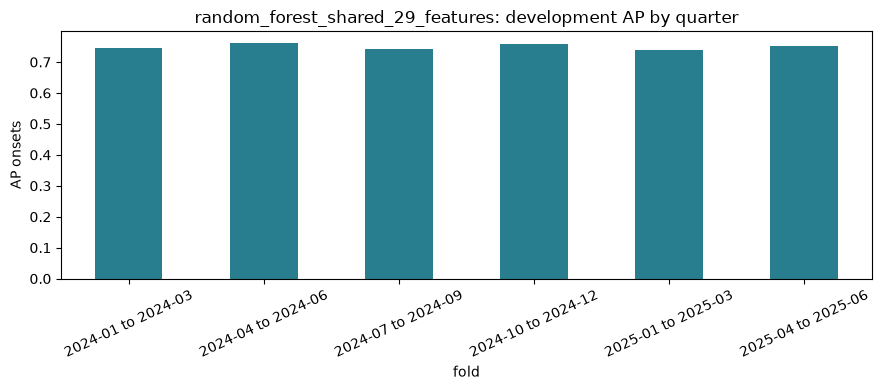

,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
model,,,,,,,,,
transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
random_forest_shared_29_features,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619
boosted_trees,2026-10-29,16,0.7494,0.0109,0.7381,0.0231,0.6251,31.1901,5.3615


Completed run: C:\Erdos\Project\safeflow\src\random_forest\results\random_forest_shared_29_features_full_20261031_200713_030817


In [5]:
metric_columns = ["AP, onsets", "AP, all", "Brier", "caught ≥15 min", "false alarms / day", "wrong-alert hours / day", "alerts right", "median lead (min)"]
table = fold_results[metric_columns].copy()
table.loc["mean"] = fold_results[metric_columns].mean()
table.loc["std"] = fold_results[metric_columns].std()
display(table.round(4))
table.to_csv(RUN_DIR / "metric_summary.csv")
fig, ax = plt.subplots(figsize=(9, 4))
fold_results["AP, onsets"].plot.bar(ax=ax, color="#287d8e")
ax.set(title=f"{MODEL_NAME}: development AP by quarter", ylabel="AP onsets")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
fig.savefig(RUN_DIR / "fold_average_precision.png", dpi=160, bbox_inches="tight")
plt.show()
team = training.publish_team_results(PROJECT_DIR, MODEL_NAME, fold_results, FEATURES, manifest, quick_run=QUICK_RUN)
if team is not None:
    display(team.set_index("model").round(4))
print("Completed run:", RUN_DIR, flush=True)